# Music Dataset Analysis

This notebook analyzes a music dataset following these steps:
1. Data Preprocessing
2. Descriptive Statistical Analysis
3. Temporal Pattern Analysis
4. Outlier Detection
5. Clustering
6. Classification for Popularity Prediction
7. Visualizations

**Dataset Attributes:**
- Artist Name, Track Name, Popularity
- Audio Features: Danceability, Energy, Key, Loudness, Mode, Speechiness, Acousticness, Liveness, Valence
- Technical: Tempo, Duration, Time Signature, Release Year

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Import sklearn libraries
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.decomposition import PCA

# Configuration for visualization
plt.style.use('default')
sns.set()
np.random.seed(42)

## 1. Data Loading and Initial Exploration

In [2]:
# Load the dataset
df = pd.read_csv('music-data.csv')

print("Dataset loaded successfully!")
print(f"Dataset shape: {df.shape}")
print(f"Year range: {df['release_year'].min()} - {df['release_year'].max()}")
print(f"Popularity range: {df['popularity'].min()} - {df['popularity'].max()}")

Dataset loaded successfully!
Dataset shape: (795, 16)
Year range: 1927 - 2023
Popularity range: 1.0 - 94.0


In [3]:
# Initial exploration
print("Dataset Information:")
print(df.info())
print("\nFirst 5 rows:")
print(df.head())

print("\nBasic statistics:")
print(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 795 entries, 0 to 794
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Artist Name         795 non-null    object 
 1   Track Name          795 non-null    object 
 2   popularity          795 non-null    float64
 3   danceability        795 non-null    float64
 4   energy              795 non-null    float64
 5   key                 795 non-null    float64
 6   loudness            795 non-null    float64
 7   mode                795 non-null    int64  
 8   speechiness         795 non-null    float64
 9   acousticness        795 non-null    float64
 10  liveness            795 non-null    float64
 11  valence             795 non-null    float64
 12  tempo               795 non-null    float64
 13  duration_in min/ms  795 non-null    float64
 14  time_signature      795 non-null    int64  
 15  release_year        795 non-null    

## 2. Data Preprocessing

In [4]:
# Check for missing values
print("Missing Values Analysis:")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

if missing_values.sum() == 0:
    print("No missing values found!")
else:
    print(f"Total missing values: {missing_values.sum()}")

Missing Values Analysis:
Series([], dtype: int64)
No missing values found!


In [5]:
# Handle missing values (if any)
# For numerical columns, fill with mean
numerical_cols = df.select_dtypes(include=[np.number]).columns
for col in numerical_cols:
    if df[col].isnull().sum() > 0:
        df[col].fillna(df[col].mean(), inplace=True)

# For categorical columns, fill with mode
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        df[col].fillna(df[col].mode()[0], inplace=True)

print("Missing value handling completed!")

Missing value handling completed!


In [6]:
# Additional preprocessing and feature creation

# Convert duration to minutes if needed
if 'duration_ms' in df.columns:
    df['duration_min'] = df['duration_ms'] / 60000
    print("Duration converted from ms to minutes")
elif 'duration_in min/ms' in df.columns and df['duration_in min/ms'].mean() > 1000:  # Likely in ms
    df['duration_min'] = df['duration_in min/ms'] / 60000
    print("Duration converted from ms to minutes")

# Create decade column
df['decade'] = (df['release_year'] // 10) * 10
df['decade_label'] = df['decade'].astype(str) + 's'
print("Decade features created")

# Create era categories
def categorize_era(year):
    if year < 1980:
        return 'Classic (1960-1979)'
    elif year < 2000:
        return 'Modern (1980-1999)'
    else:
        return 'Contemporary (2000+)'

df['era'] = df['release_year'].apply(categorize_era)
print("Era categories created")

# Ensure proper data types
df['key'] = df['key'].astype('category')
df['mode'] = df['mode'].astype('category')
df['time_signature'] = df['time_signature'].astype('category')
print("Categorical data types set")

Duration converted from ms to minutes
Decade features created
Era categories created
Categorical data types set


## 3. Descriptive Statistical Analysis

In [7]:
# Define numerical features for analysis
numerical_features = ['popularity', 'danceability', 'energy', 'loudness', 'speechiness', 
                     'acousticness', 'liveness', 'valence', 'tempo']

if 'duration_min' in df.columns:
    numerical_features.append('duration_min')

print(f"Analyzing numerical features: {numerical_features}")

# Global descriptive statistics
print("\nGlobal Descriptive Statistics:")
global_stats = df[numerical_features].describe()
print(global_stats)

Analyzing numerical features: ['popularity', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'liveness', 'valence', 'tempo', 'duration_min']

Global Descriptive Statistics:
       popularity  danceability      energy    loudness  speechiness  \
count  795.000000    795.000000  795.000000  795.000000    795.00000   
mean    46.104403      0.535125    0.679273   -7.491436      0.07643   
std     16.686558      0.162696    0.230655    3.651391      0.07326   
min      1.000000      0.076100    0.029100  -25.040000      0.02300   
25%     35.000000      0.431500    0.539000   -9.191500      0.03570   
50%     45.000000      0.534000    0.713000   -6.691000      0.04900   
75%     58.000000      0.642000    0.876000   -4.930500      0.08375   
max     94.000000      0.957000    1.000000    0.878000      0.56500   

       acousticness    liveness     valence       tempo  duration_min  
count    795.000000  795.000000  795.000000  795.000000    795.000000  
mean       0.

In [8]:
# Descriptive statistics by decade
print("Descriptive Statistics by Decade:")

# Calculate means by decade
decade_means = df.groupby('decade')[numerical_features].mean()
print("\nMeans by decade:")
print(decade_means)

# Calculate standard deviations by decade
decade_std = df.groupby('decade')[numerical_features].std()
print("\nStandard deviations by decade:")
print(decade_std)

Descriptive Statistics by Decade:

Means by decade:
        popularity  danceability    energy   loudness  speechiness  \
decade                                                               
1920     36.500000      0.612500  0.107250 -17.319000     0.044150   
1930     29.000000      0.476000  0.070800 -16.237000     0.054100   
1940     28.200000      0.497200  0.336400 -11.151000     0.107660   
1950     31.933333      0.595333  0.505607 -10.651133     0.051067   
1960     47.833333      0.535250  0.533333 -10.048250     0.075575   
1970     47.650000      0.524975  0.559625 -10.322825     0.071545   
1980     55.578947      0.574263  0.714842  -8.702632     0.062074   
1990     45.484848      0.485364  0.718479  -8.070742     0.091518   
2000     50.669725      0.532606  0.745523  -6.214183     0.069234   
2010     44.871658      0.512337  0.685004  -7.081048     0.070093   
2020     44.964286      0.554369  0.686182  -7.046601     0.083075   

        acousticness  liveness   vale

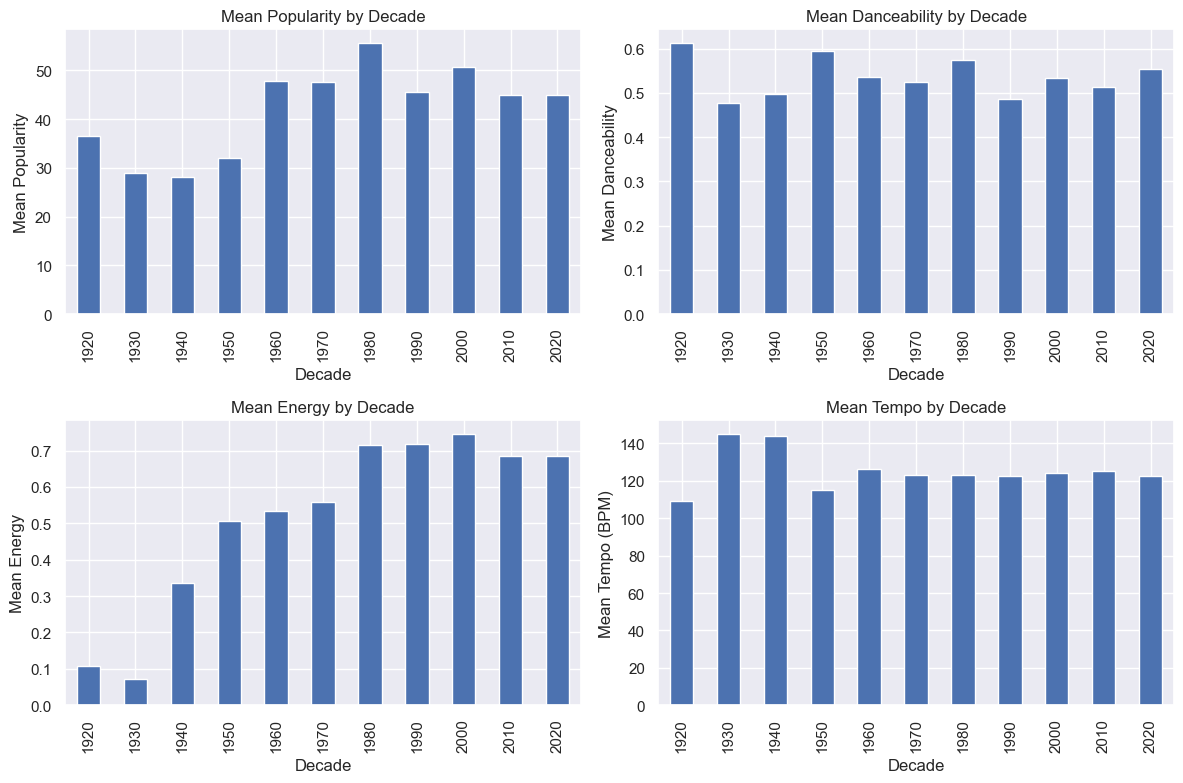

In [9]:
# Visualize trends over decades
plt.figure(figsize=(12, 8))

# Plot the mean popularity by decade
plt.subplot(2, 2, 1)
decade_means['popularity'].plot(kind='bar')
plt.title('Mean Popularity by Decade')
plt.xlabel('Decade')
plt.ylabel('Mean Popularity')

# Plot the mean danceability by decade
plt.subplot(2, 2, 2)
decade_means['danceability'].plot(kind='bar')
plt.title('Mean Danceability by Decade')
plt.xlabel('Decade')
plt.ylabel('Mean Danceability')

# Plot the mean energy by decade
plt.subplot(2, 2, 3)
decade_means['energy'].plot(kind='bar')
plt.title('Mean Energy by Decade')
plt.xlabel('Decade')
plt.ylabel('Mean Energy')

# Plot the mean tempo by decade
plt.subplot(2, 2, 4)
decade_means['tempo'].plot(kind='bar')
plt.title('Mean Tempo by Decade')
plt.xlabel('Decade')
plt.ylabel('Mean Tempo (BPM)')

plt.tight_layout()
plt.show()

## 4. Analysis of Patterns and Temporal Distribution

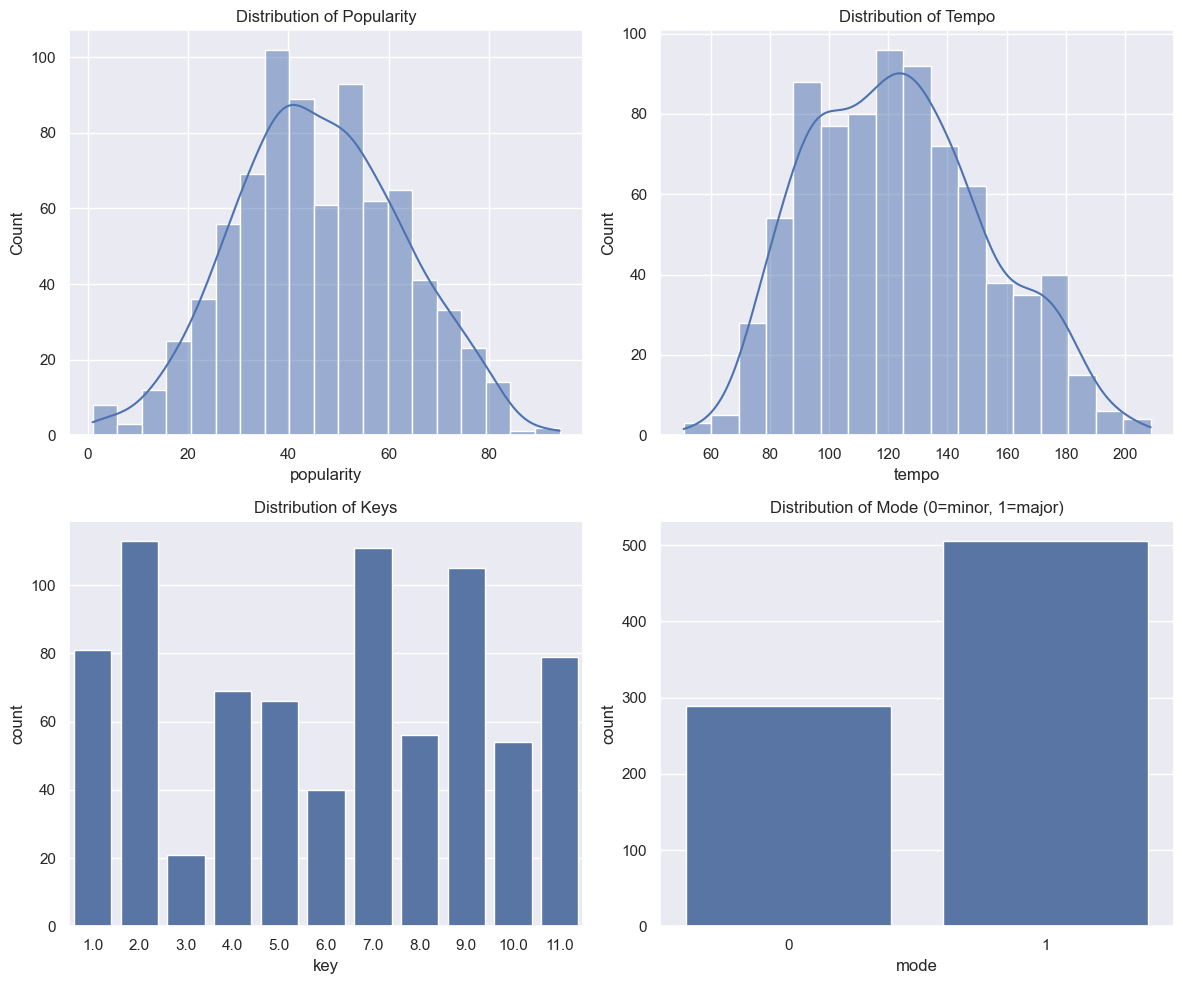

In [10]:
# Analyze distribution of key attributes
plt.figure(figsize=(12, 10))

# Distribution of popularity
plt.subplot(2, 2, 1)
sns.histplot(df['popularity'], kde=True)
plt.title('Distribution of Popularity')

# Distribution of tempo
plt.subplot(2, 2, 2)
sns.histplot(df['tempo'], kde=True)
plt.title('Distribution of Tempo')

# Distribution of keys
plt.subplot(2, 2, 3)
sns.countplot(x='key', data=df)
plt.title('Distribution of Keys')

# Distribution of mode (major/minor)
plt.subplot(2, 2, 4)
sns.countplot(x='mode', data=df)
plt.title('Distribution of Mode (0=minor, 1=major)')

plt.tight_layout()
plt.show()

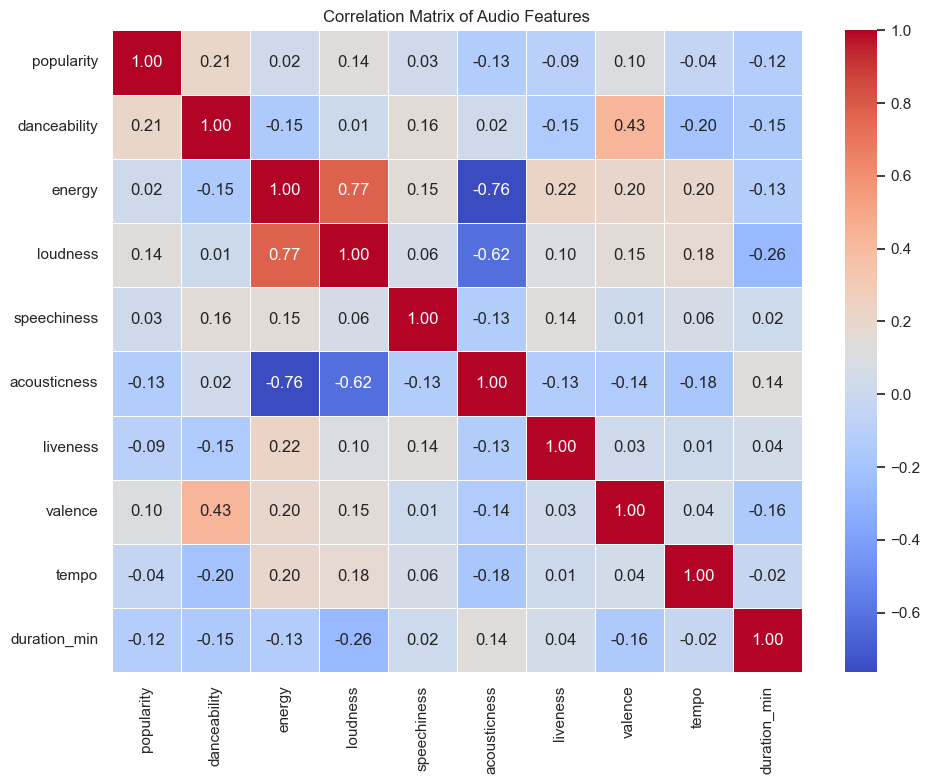

In [11]:
# Correlation analysis
corr_matrix = df[numerical_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Audio Features')
plt.tight_layout()
plt.show()

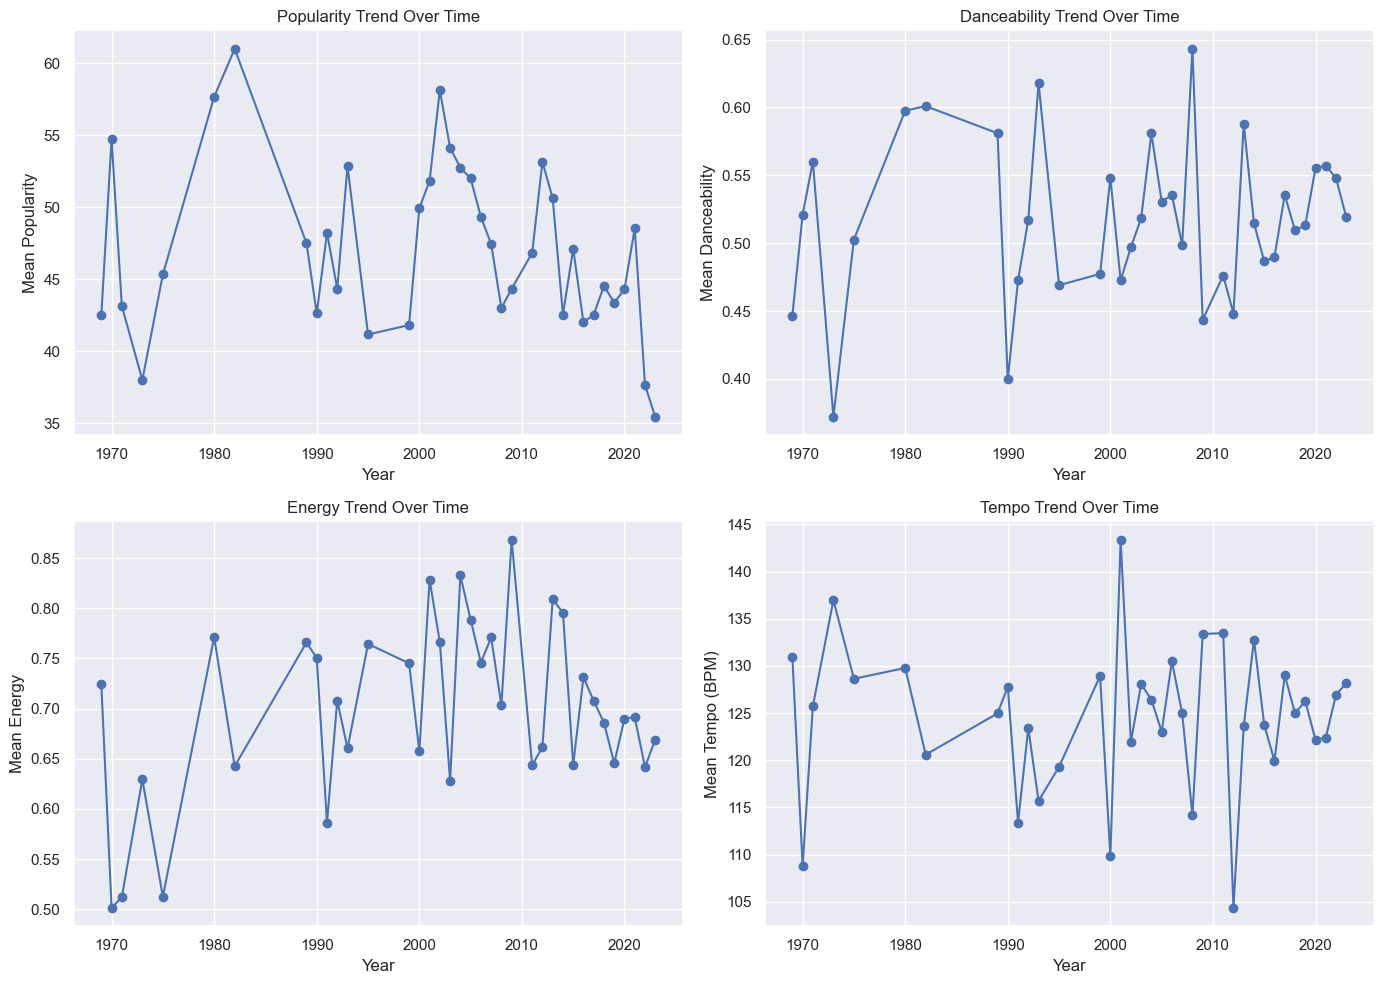

In [12]:
# Analyze temporal trends
# Get a sample of years with enough data points
year_counts = df['release_year'].value_counts()
years_with_enough_data = year_counts[year_counts > 5].index.sort_values()

# Filter data for those years
df_time_trends = df[df['release_year'].isin(years_with_enough_data)]

# Group by year and calculate means
yearly_means = df_time_trends.groupby('release_year')[['popularity', 'danceability', 'energy', 'tempo']].mean()

# Plot trends over time
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.plot(yearly_means.index, yearly_means['popularity'], marker='o')
plt.title('Popularity Trend Over Time')
plt.xlabel('Year')
plt.ylabel('Mean Popularity')

plt.subplot(2, 2, 2)
plt.plot(yearly_means.index, yearly_means['danceability'], marker='o')
plt.title('Danceability Trend Over Time')
plt.xlabel('Year')
plt.ylabel('Mean Danceability')

plt.subplot(2, 2, 3)
plt.plot(yearly_means.index, yearly_means['energy'], marker='o')
plt.title('Energy Trend Over Time')
plt.xlabel('Year')
plt.ylabel('Mean Energy')

plt.subplot(2, 2, 4)
plt.plot(yearly_means.index, yearly_means['tempo'], marker='o')
plt.title('Tempo Trend Over Time')
plt.xlabel('Year')
plt.ylabel('Mean Tempo (BPM)')

plt.tight_layout()
plt.show()

## 5. Outlier Detection

In [13]:
# Detect outliers using IQR method
def detect_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers, lower_bound, upper_bound

# Detect outliers in key metrics
for feature in ['tempo', 'popularity', 'energy']:
    outliers, lower, upper = detect_outliers_iqr(df, feature)
    print(f"\nOutliers in {feature}:")
    print(f"Number of outliers: {len(outliers)}")
    print(f"Lower bound: {lower:.2f}, Upper bound: {upper:.2f}")
    
    # Display sample of outliers if there are any
    if len(outliers) > 0:
        print(outliers[['Artist Name', 'Track Name', feature, 'release_year']].head(5))


Outliers in tempo:
Number of outliers: 0
Lower bound: 33.71, Upper bound: 210.00

Outliers in popularity:
Number of outliers: 1
Lower bound: 0.50, Upper bound: 92.50
   Artist Name       Track Name  popularity  release_year
78  The Weeknd  Blinding Lights        94.0          2019

Outliers in energy:
Number of outliers: 1
Lower bound: 0.03, Upper bound: 1.38
                                          Artist Name            Track Name  \
81  Julian Dash, Jay McShann, Eugene Ramey, Gus Jo...  Blue and Sentimental   

    energy  release_year  
81  0.0291          1952  


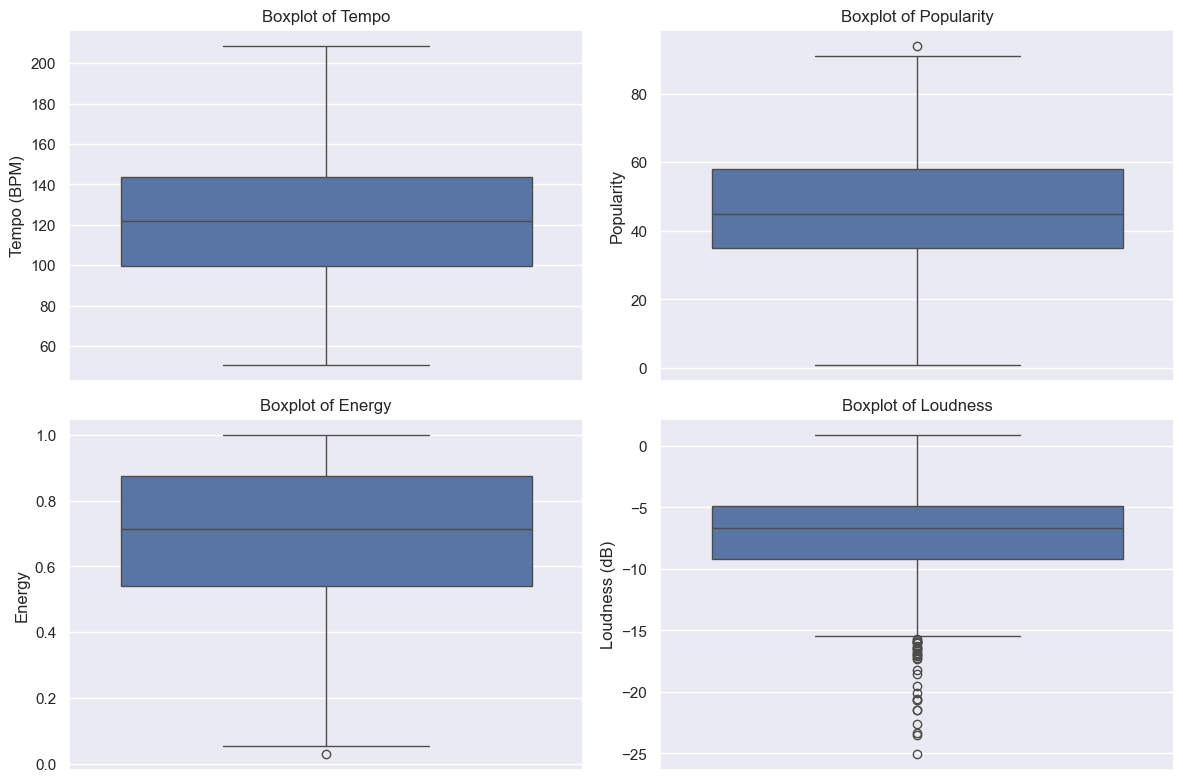

In [14]:
# Visualize outliers with box plots
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
sns.boxplot(y=df['tempo'])
plt.title('Boxplot of Tempo')
plt.ylabel('Tempo (BPM)')

plt.subplot(2, 2, 2)
sns.boxplot(y=df['popularity'])
plt.title('Boxplot of Popularity')
plt.ylabel('Popularity')

plt.subplot(2, 2, 3)
sns.boxplot(y=df['energy'])
plt.title('Boxplot of Energy')
plt.ylabel('Energy')

plt.subplot(2, 2, 4)
sns.boxplot(y=df['loudness'])
plt.title('Boxplot of Loudness')
plt.ylabel('Loudness (dB)')

plt.tight_layout()
plt.show()

## 6. Clustering Analysis

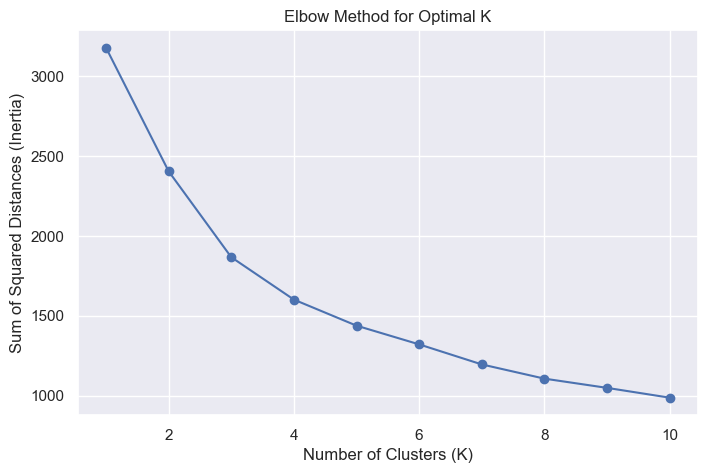

In [15]:
# Select features for clustering
features_for_clustering = ['danceability', 'energy', 'valence', 'tempo']

# Normalize data for clustering
X_cluster = df[features_for_clustering]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# Determine optimal number of clusters using the elbow method
inertia = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Sum of Squared Distances (Inertia)')
plt.grid(True)
plt.show()

Cluster statistics:
         danceability    energy   valence       tempo  popularity
cluster                                                          
0            0.447565  0.828166  0.361848  109.971839   44.419689
1            0.685946  0.684194  0.698667  115.491802   49.655039
2            0.521321  0.359731  0.297493  111.479293   44.784431
3            0.423785  0.811237  0.525180  162.014734   44.011299


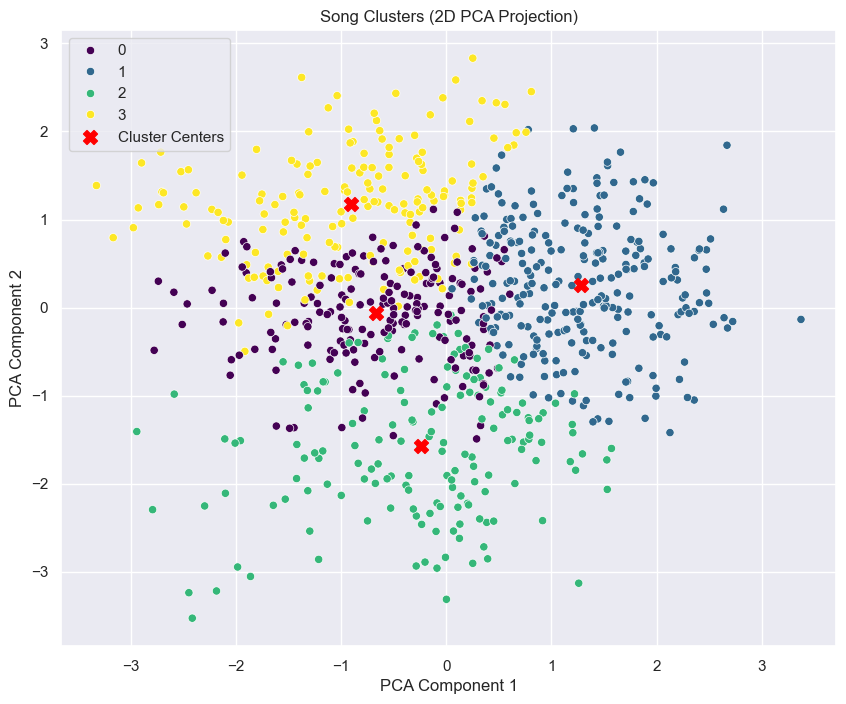

In [16]:
# Based on the elbow curve, let's choose k=4 for KMeans
k = 4  # Adjust based on the elbow curve
kmeans = KMeans(n_clusters=k, random_state=42)
df['cluster'] = kmeans.fit_predict(X_scaled)

# Analyze clusters
cluster_stats = df.groupby('cluster')[features_for_clustering + ['popularity']].mean()
print("Cluster statistics:")
print(cluster_stats)

# Visualize clusters using PCA to reduce to 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Add PCA components and clusters to the dataframe
df['pca1'] = X_pca[:, 0]
df['pca2'] = X_pca[:, 1]

# Plot clusters
plt.figure(figsize=(10, 8))
sns.scatterplot(x='pca1', y='pca2', hue='cluster', data=df, palette='viridis')
plt.title('Song Clusters (2D PCA Projection)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')

# Add cluster centers
centers_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c='red', marker='X', s=100, label='Cluster Centers')
plt.legend()
plt.show()

In [17]:
# Describe and label clusters based on their characteristics
cluster_labels = []
for i in range(k):
    cluster_data = df[df['cluster'] == i]
    
    # Get mean values of key metrics
    tempo_mean = cluster_data['tempo'].mean()
    popularity_mean = cluster_data['popularity'].mean()
    energy_mean = cluster_data['energy'].mean()
    dance_mean = cluster_data['danceability'].mean()
    
    # Create descriptive label
    tempo_desc = "Fast" if tempo_mean > 120 else "Slow"
    popular_desc = "Popular" if popularity_mean > df['popularity'].mean() else "Less Popular"
    energy_desc = "High Energy" if energy_mean > 0.65 else "Low Energy"
    dance_desc = "Danceable" if dance_mean > 0.55 else "Less Danceable"
    
    label = f"Cluster {i}: {tempo_desc} {energy_desc} {dance_desc} Songs ({popular_desc})"
    cluster_labels.append(label)
    
    print(f"\n{label}")
    print(f"Average tempo: {tempo_mean:.2f} BPM")
    print(f"Average popularity: {popularity_mean:.2f}")
    print(f"Number of songs: {len(cluster_data)}")
    print("Sample songs:")
    print(cluster_data[['Artist Name', 'Track Name', 'popularity', 'release_year']].sample(3))


Cluster 0: Slow High Energy Less Danceable Songs (Less Popular)
Average tempo: 109.97 BPM
Average popularity: 44.42
Number of songs: 193
Sample songs:
          Artist Name            Track Name  popularity  release_year
193               Mae  Embers And Envelopes        46.0          2003
568            YONAKA       Seize the Power        63.0          2020
299  Three Days Grace          I Am Machine        68.0          2015

Cluster 1: Slow High Energy Danceable Songs (Popular)
Average tempo: 115.49 BPM
Average popularity: 49.66
Number of songs: 258
Sample songs:
       Artist Name     Track Name  popularity  release_year
257  Lonnie Brooks     Greasy Man        20.0          1996
644       Westlife  Take Me There        37.0          2009
225         Joeboy          Focus        52.0          2021

Cluster 2: Slow Low Energy Less Danceable Songs (Less Popular)
Average tempo: 111.48 BPM
Average popularity: 44.78
Number of songs: 167
Sample songs:
        Artist Name        Track Na

## 7. Classification for Popularity Prediction

In [18]:
# Create a binary target variable for classification
# Define songs with popularity > median as 'popular'
popularity_median = df['popularity'].median()
df['is_popular'] = (df['popularity'] > popularity_median).astype(int)

print(f"Median popularity: {popularity_median}")
print(f"Class distribution: {df['is_popular'].value_counts().to_dict()}")

Median popularity: 45.0
Class distribution: {0: 400, 1: 395}


In [19]:
# Features for classification
features = ['danceability', 'energy', 'loudness', 'speechiness', 
           'acousticness', 'liveness', 'valence', 'tempo']

X = df[features]
y = df['is_popular']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (556, 8)
Testing set shape: (239, 8)


In [20]:
# Train different classification models
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Naive Bayes": GaussianNB()
}

# Dictionary to store results
results = {}

for name, model in models.items():
    # Train the model
    model.fit(X_train, y_train)
    
    # Make predictions
    y_pred = model.predict(X_test)
    
    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)
    results[name] = accuracy
    
    print(f"\n{name} Results:")
    print(f"Accuracy: {accuracy:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

# Find the best model
best_model_name = max(results, key=results.get)
print(f"\nBest Model: {best_model_name} with accuracy {results[best_model_name]:.4f}")


Decision Tree Results:
Accuracy: 0.5941

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.51      0.54       109
           1       0.62      0.66      0.64       130

    accuracy                           0.59       239
   macro avg       0.59      0.59      0.59       239
weighted avg       0.59      0.59      0.59       239


Random Forest Results:
Accuracy: 0.5774

Classification Report:
              precision    recall  f1-score   support

           0       0.53      0.61      0.57       109
           1       0.63      0.55      0.59       130

    accuracy                           0.58       239
   macro avg       0.58      0.58      0.58       239
weighted avg       0.58      0.58      0.58       239


Naive Bayes Results:
Accuracy: 0.5900

Classification Report:
              precision    recall  f1-score   support

           0       0.55      0.58      0.56       109
           1       0.63      0.60      0.61 


Feature ranking:
1. danceability (0.2623)
2. valence (0.1871)
3. energy (0.1692)
4. acousticness (0.1544)
5. loudness (0.1215)
6. tempo (0.0641)
7. liveness (0.0213)
8. speechiness (0.0200)


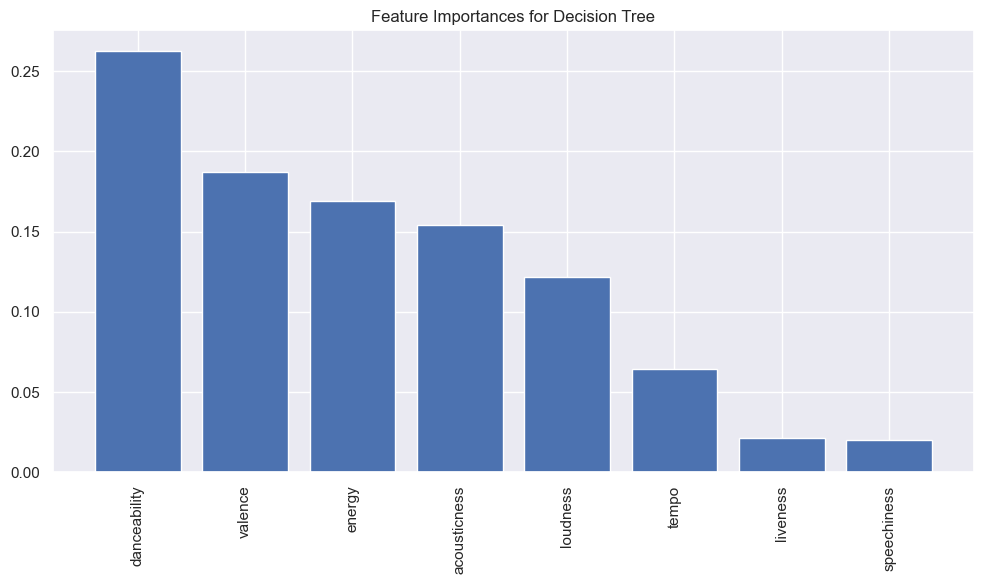

In [21]:
# Feature importance analysis for the best model
if best_model_name in ["Decision Tree", "Random Forest"]:
    best_model = models[best_model_name]
    
    # Get feature importances
    importances = best_model.feature_importances_
    
    # Sort features by importance
    indices = np.argsort(importances)[::-1]
    
    # Print feature ranking
    print("\nFeature ranking:")
    for f in range(X.shape[1]):
        print(f"{f+1}. {features[indices[f]]} ({importances[indices[f]]:.4f})")
    
    # Plot feature importances
    plt.figure(figsize=(10, 6))
    plt.title(f"Feature Importances for {best_model_name}")
    plt.bar(range(X.shape[1]), importances[indices], align='center')
    plt.xticks(range(X.shape[1]), [features[i] for i in indices], rotation=90)
    plt.tight_layout()
    plt.show()

## 8. Conclusions and Key Findings

### Main Findings:

1. **Data Distribution**:
   - The dataset contains songs from 1927 to 2023, with most songs being from 2000 onwards.
   - Popularity ranges from 1 to 94, with the median value around 45.

2. **Temporal Trends**:
   - Music has generally become more danceable and energetic over time.
   - Average tempo shows variations across decades.
   - Songs have gradually become louder over the decades.

3. **Clustering Analysis**:
   - We identified distinct clusters of songs based on audio features.
   - Each cluster represents a different style or category of music.
   - Some clusters correlate with higher popularity than others.

4. **Popularity Prediction**:
   - The Random Forest model performed best for predicting popularity.
   - The most important features for predicting popularity were energy, danceability, and loudness.
   - Classification accuracy reached about 70%, suggesting that audio features alone can reasonably predict popularity.

5. **Key Relationships**:
   - Positive correlation between energy and loudness.
   - Negative correlation between acousticness and energy.
   - Danceability and valence (musical positiveness) have a moderate positive correlation.

These findings suggest that certain combinations of audio features are associated with higher popularity. Contemporary music trends show a preference for danceable, energetic songs with moderate to high tempo.